# 00 — Environment and public-source feasibility

This notebook inspects the public samples collected on 15 September 2026. It is
not a complete-feed audit or a forecasting experiment. The seven public Yahoo
collection files were inspected completely; their sampling process remains unverified.
GDELT observations are five
selected 15-minute batches, and FNSPID observations are two contiguous file
prefixes. Neither sample is representative of the complete corpus.

**Holdout rule:** date availability and source metadata may be summarized over all
years. Return/volatility EDA below is limited to 2017–2022. No final-period model
performance is inspected. Raw files remain under Git-ignored `data/`.


In [1]:
import csv
import hashlib
import json
from datetime import datetime
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'PROJECT_BLUEPRINT.md').exists())
probe = json.loads((ROOT / 'docs/research/public_source_probe.json').read_text())
retained = json.loads((ROOT / 'docs/research/retained_sample_audit.json').read_text())
RAW = ROOT / 'data/raw/feasibility_20260915'
print('Retained audit:', retained['retrieved_at_utc'])
print('Snapshots:', len(retained['snapshots']))
for item in retained['snapshots']:
    if 'error' in item:
        raise RuntimeError(item['error'])
    payload = (ROOT / item['path']).read_bytes()
    assert hashlib.sha256(payload).hexdigest() == item['sha256']
    del payload
print('All retained source checksums match.')


Retained audit: 2026-09-15T14:48:20.580556+00:00
Snapshots: 7


All retained source checksums match.


## 1. File-prefix timestamp evidence
Midnight concentration is a warning about precision/provenance, not a measured corpus-wide rejection rate.

In [2]:
for item in probe['sources']:
    if item['name'].startswith('fnspid'):
        n = item['parsed_rows']
        print(f"{item['name']}: {item['midnight_rows']}/{n} midnight ({item['midnight_rows']/n:.2%}), {item['distinct_symbols']} symbols")
print('Decision: do not admit FNSPID to the primary intraday-ordering study without timestamp provenance.')


fnspid_external_prefix: 4563/4605 midnight (99.09%), 5 symbols
fnspid_nasdaq_prefix: 152/153 midnight (99.35%), 1 symbols
Decision: do not admit FNSPID to the primary intraday-ordering study without timestamp provenance.


## 2. Retained market data and join integrity
Count actual observations. A complete exchange-calendar audit remains a later gate; FRED nonmissing dates are only a provisional grid for this check.

In [3]:
with (RAW / 'fred_sp500.csv').open(encoding='utf-8-sig', newline='') as f:
    sp = {datetime.strptime(r['observation_date'], '%Y-%m-%d').date(): float(r['SP500']) for r in csv.DictReader(f) if r['SP500'] not in ('', '.')}
with (RAW / 'cboe_vix.csv').open(encoding='utf-8-sig', newline='') as f:
    vix = {datetime.strptime(r['DATE'], '%m/%d/%Y').date(): float(r['CLOSE']) for r in csv.DictReader(f)}
missing = sorted(set(sp) - set(vix))
extra = [d.isoformat() for d in sorted(set(vix) - set(sp)) if 2022 <= d.year <= 2025]
print('VIX missing on nonmissing SP500 dates:', len(missing))
print('VIX extra dates in 2022–2025:', len(extra))
print(extra)
for start, end, label in [(2017, 2020, 'Alpaca initial training'), (2020, 2021, 'GDELT-title initial training'), (2021, 2022, 'Alpaca development'), (2022, 2022, 'GDELT-title development'), (2023, 2025, 'Final test')]:
    print(label, sum(start <= d.year <= end for d in sp), 'market observations before news/label-availability exclusions')
assert not missing


VIX missing on nonmissing SP500 dates: 0
VIX extra dates in 2022–2025: 27
['2022-05-30', '2022-06-20', '2022-07-04', '2022-09-05', '2022-11-24', '2023-01-16', '2023-02-20', '2023-05-29', '2023-06-19', '2023-07-04', '2023-09-04', '2023-11-23', '2024-01-15', '2024-02-19', '2024-05-27', '2024-06-19', '2024-07-04', '2024-09-02', '2024-11-28', '2025-01-09', '2025-01-20', '2025-02-17', '2025-05-26', '2025-06-19', '2025-07-04', '2025-09-01', '2025-11-27']
Alpaca initial training 1007 market observations before news/label-availability exclusions
GDELT-title initial training 505 market observations before news/label-availability exclusions
Alpaca development 503 market observations before news/label-availability exclusions
GDELT-title development 251 market observations before news/label-availability exclusions
Final test 752 market observations before news/label-availability exclusions


## 3. Development-period market EDA
Simple returns are calculated on the observed price-date grid solely for exploratory diagnostics. The production label builder must verify adjacency against the pinned exchange calendar.

Development returns: 1510
Mean daily return: 0.000438
Daily standard deviation: 0.012691
Min / max: -0.119841 0.093828


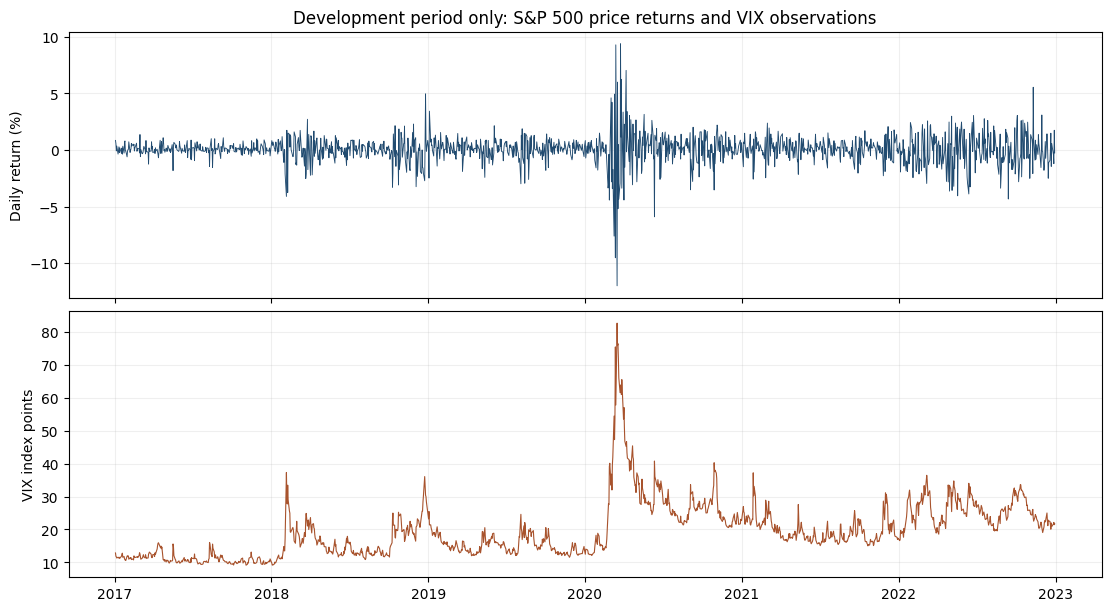

In [4]:
import math
import statistics
import matplotlib.pyplot as plt

dates = sorted(sp)
dev = [(dates[i], sp[dates[i]] / sp[dates[i-1]] - 1) for i in range(1, len(dates)) if 2017 <= dates[i].year <= 2022]
ret = [value for date, value in dev]
print('Development returns:', len(ret))
print('Mean daily return:', round(statistics.mean(ret), 6))
print('Daily standard deviation:', round(statistics.stdev(ret), 6))
print('Min / max:', round(min(ret), 6), round(max(ret), 6))
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, constrained_layout=True)
axes[0].plot([d for d, r in dev], [100*r for d, r in dev], linewidth=0.65, color='#214b70')
axes[0].set_ylabel('Daily return (%)')
axes[0].set_title('Development period only: S&P 500 price returns and VIX observations')
axes[1].plot([d for d, r in dev], [vix[d] for d, r in dev], linewidth=0.8, color='#a8532d')
axes[1].set_ylabel('VIX index points')
for ax in axes:
    ax.grid(alpha=0.2)
out = ROOT / 'artifacts/reports/feasibility'
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / 'development_market_eda.png', dpi=150)
plt.show()


## 4. Archived GDELT titles
Archived page titles are materially different from re-fetching today's article text at an old URL. Batch timestamps still require an explicit historical-availability assumption.

In [5]:
slices = [x for x in retained['snapshots'] if x['name'].endswith('.zip')]
for item in slices:
    a = item['audit']
    print(a['batch'], 'rows=', a['rows'], 'titles=', a['with_title'], 'title_fraction=', round(a['with_title']/a['rows'], 4), 'selected finance-domain rows=', a['selected_finance_domains'])
    assert len(a['distinct_date_values']) == 1
print('Bytes retained:', sum(x['bytes'] for x in retained['snapshots']))
mean_bytes = statistics.mean(x['bytes'] for x in slices)
scenario = mean_bytes * 96 * 365.25 * 6 / 2**40
print('Illustrative six-year global-archive transfer at this sample mean:', round(scenario, 2), 'TiB')
print('This is a rough scenario, not a representative archive-size estimate.')


20170103200000 rows= 4048 titles= 0 title_fraction= 0.0 selected finance-domain rows= 57
20200316200000 rows= 2830 titles= 2817 title_fraction= 0.9954 selected finance-domain rows= 48
20220613200000 rows= 1782 titles= 1780 title_fraction= 0.9989 selected finance-domain rows= 7
20230313200000 rows= 1685 titles= 1684 title_fraction= 0.9994 selected finance-domain rows= 23
20250403200000 rows= 2036 titles= 2030 title_fraction= 0.9971 selected finance-domain rows= 1
Bytes retained: 49136415
Illustrative six-year global-archive transfer at this sample mean: 1.86 TiB
This is a rough scenario, not a representative archive-size estimate.


## 5. Full-file Yahoo research collection audit

All seven compressed original-source files were parsed by a streaming reader.
The table below reports recorded metadata, not verified delivery times or unique
article counts. Negative crawl lags require investigation. Supplied price,
sentiment, emotion, and entity-enrichment fields are excluded from project inputs.


In [6]:
yahoo = json.loads((ROOT / 'docs/research/yahoo_collection_audit.json').read_text())
for item in yahoo['files']:
    with (ROOT / item['path']).open('rb') as f:
        assert hashlib.file_digest(f, 'sha256').hexdigest() == item['sha256']
    print(item['year_file'], 'rows=', item['rows'], 'publication_days=', item['publication_days'], 'median_crawl_lag_hours=', round(item['median_crawl_lag_hours'], 2), 'negative_lags=', item['negative_crawl_lag'])
print('Total records:', yahoo['total_rows'])
print('Total compressed bytes:', yahoo['total_bytes'])
print('Negative publication-to-crawl lags:', sum(x['negative_crawl_lag'] for x in yahoo['files']))
print('Rows with a modification time:', sum(x['with_modified_time'] for x in yahoo['files']))
print('All Yahoo file hashes match. File completeness does not establish feed completeness.')


2017 rows= 403 publication_days= 195 median_crawl_lag_hours= 7.96 negative_lags= 0
2018 rows= 407 publication_days= 151 median_crawl_lag_hours= 2.0 negative_lags= 6
2019 rows= 1588 publication_days= 223 median_crawl_lag_hours= 1.2 negative_lags= 7
2020 rows= 1855 publication_days= 177 median_crawl_lag_hours= 1.1 negative_lags= 11
2021 rows= 20706 publication_days= 324 median_crawl_lag_hours= 0.73 negative_lags= 0
2022 rows= 21204 publication_days= 295 median_crawl_lag_hours= 0.77 negative_lags= 0


2023 rows= 24811 publication_days= 329 median_crawl_lag_hours= 0.83 negative_lags= 37
Total records: 70974
Total compressed bytes: 105919076
Negative publication-to-crawl lags: 61
Rows with a modification time: 0
All Yahoo file hashes match. File completeness does not establish feed completeness.


## 6. Decisions supported by this inspection

- FRED/Cboe files are retrievable and retained with hashes. A row-position join is invalid: VIX contains extra dates.
- FNSPID cannot be the default until its apparent timestamp precision is explained.
- GDELT archived titles support a public-text candidate from late 2019 onward; a 2020–2025 title study is plausible, with a shorter initial training period.
- A small set of current finance-domain names is not a demonstrated stable historical news universe. Audit theme-based relevance and source coverage before fixing a filter.
- Bulk local GKG download is not justified. Test a bounded server-side extraction and full-window completeness before making a multi-year commitment.
- The Yahoo collection is suitable for bounded engineering EDA, but its early coverage is sparse, its sampling/version provenance needs work, and its publication-year files end in 2023. It is not the source for the preferred 2023–2025 final test.
- A free Alpaca news pilot is a practical alternative if bounded GDELT extraction fails; account entitlement, delay, and actual news quota remain unverified.
- None of these results certifies point-in-time historical availability, proves news coverage, or establishes forecast improvement.

See `PROJECT_BLUEPRINT.md` for the authoritative conditional source-selection rule,
resource gates, data contracts, and experiment specification.
